# Prediksi Suhu Udara 1 Jam ke Depan dengan XGBoost (Jena Climate)

**Milestone 1 (UTS) - IF2116 Pembelajaran Mesin** | Program Studi S-1 Teknik Informatika, Universitas Mikroskil

Penyusun: Athaya Naufal Brasta (231112230) dan Nicholas Jogi Nathanael (231111989)

---

## Ringkasan
- **Masalah:** memprediksi suhu udara (°C) **60 menit ke depan** dari data cuaca historis (regresi pada data deret waktu).
- **Pendekatan:** *classical machine learning* (model pohon berbasis *gradient boosting*) dengan fitur riwayat (*lag*) dan siklus waktu.
- **Dataset:** Jena Climate 2009-2016 (420.551 baris x 15 kolom), pengamatan setiap 10 menit.
  Sumber: https://huggingface.co/datasets/sayanroy058/Jena-Climate (berkas `jena_climate_2009_2016.csv`).
  Data asli dicatat oleh stasiun cuaca Max Planck Institute for Biogeochemistry, Jena, Jerman.

## Cara menjalankan ulang
1. Buka di Google Colab (atau Jupyter dengan Python 3.9+), lalu pilih **Runtime > Run all**.
2. Dibutuhkan koneksi internet karena data diunduh langsung dari Hugging Face pada sel bagian 1. Jika koneksi tidak tersedia, unduh berkas CSV dari tautan di atas, lalu ganti isi variabel `url` pada sel bagian 1 dengan jalur berkas lokal.
3. Library yang dipakai: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `xgboost`. Di Google Colab semuanya sudah tersedia.
4. Estimasi waktu: sekitar 10-20 menit (sebagian besar untuk validasi silang Random Forest).
5. Semua angka, tabel, dan gambar hasil disimpan ke folder `hasil_eksperimen/`. Sel terakhir mencetak **Lembar Isian Laporan** agar angka di laporan dapat ditelusuri ke notebook ini.

## Peta komponen UTS terhadap notebook
| Komponen UTS | Bagian notebook |
|---|---|
| A. Problem formulation | Ringkasan di atas dan bagian A-B |
| B. Dataset dan data understanding | Bagian 1 dan 1b |
| C. EDA dan initial findings | Bagian 3 dan 3D |
| D. Preprocessing | Bagian 2 dan G1 (audit *data leakage*) |
| E. Initial feature engineering | Bagian 2 dan H1 (ablasi fitur) |
| F. Baseline dan model kandidat | Bagian F1, F2, dan F3 |
| G. Evaluation design | Bagian 4, G1, dan F2 |
| H. Initial results and analysis | Bagian 5-7 dan H1-H4 |
| I. Documentation dan next plan | Bagian I di akhir notebook |



In [1]:
# Jalankan hanya jika library belum tersedia (Google Colab biasanya sudah lengkap).
# !pip install -q xgboost scikit-learn pandas numpy matplotlib seaborn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

In [ ]:
import os
import warnings
import platform
import sklearn
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUT_DIR = "hasil_eksperimen"          
os.makedirs(OUT_DIR, exist_ok=True)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgb.__version__}")

Python 3.13.16 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | xgboost 3.4.1


---
# A-B. Problem Formulation dan Dataset

**Rumusan masalah.** Berapa suhu udara 60 menit setelah suatu pengamatan, jika diketahui kondisi cuaca saat ini dan riwayat 10, 30, dan 60 menit sebelumnya?

- **Jenis tugas:** supervised learning, **regresi** pada data deret waktu (*time series forecasting* yang dibingkai sebagai regresi tabular dengan fitur *lag*).
- **Target:** `target_suhu_next_hour` = `T (degC)` pada t + 60 menit (nilai pengukuran sensor, bukan label buatan).
- **Unit observasi:** satu pengamatan cuaca (satu baris) setiap 10 menit.
- **Metrik utama:** MAE, RMSE, R², dan *skill score* terhadap baseline persistensi.

# 1. Load Data dan Audit Kualitas Data Awal

In [4]:
# ==============================================================================
# 1. LOAD DATA & AUDIT KUALITAS DATA AWAL
# ==============================================================================
print("--- 1. AUDIT KUALITAS DATA AWAL (RAW DATA) ---")
url = "https://huggingface.co/datasets/sayanroy058/Jena-Climate/resolve/main/jena_climate_2009_2016.csv"
df = pd.read_csv(url)

print(f"Dimensi Data Mentah (Baris, Kolom): {df.shape}")
print(f"Total Duplikat Baris: {df.duplicated().sum()}")
missing_raw = df.isnull().sum()
print("Jumlah Missing Values per Kolom:")
print(missing_raw[missing_raw > 0] if missing_raw.sum() > 0 else "Nol (Dataset utuh tanpa nilai NaN bawaan).")

# Sensor error: Anomali nilai kecepatan angin negatif (-9999 m/s)
sensor_errors = (df["wv (m/s)"] < 0).sum()
print(f"Anomali Nilai Sensor Negatif pada 'wv (m/s)': {sensor_errors} baris (akan di-handle)\n")

--- 1. AUDIT KUALITAS DATA AWAL (RAW DATA) ---
Dimensi Data Mentah (Baris, Kolom): (420551, 15)
Total Duplikat Baris: 327
Jumlah Missing Values per Kolom:
Nol (Dataset utuh tanpa nilai NaN bawaan).
Anomali Nilai Sensor Negatif pada 'wv (m/s)': 18 baris (akan di-handle)



In [5]:
# ==============================================================================
# [BARU] 1b. DATA UNDERSTANDING TAMBAHAN (tidak mengubah df)
# ==============================================================================
print("--- 1b. DATA UNDERSTANDING TAMBAHAN ---")
raw_shape = df.shape                    # ukuran data mentah sebenarnya (sebelum feature engineering)
print(f"Ukuran data mentah sebenarnya (baris, kolom): {raw_shape}")
print("\nTipe data per kolom:")
print(df.dtypes.to_string())

_ts = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
print(f"\nRentang waktu             : {_ts.min()} s.d. {_ts.max()}")
print(f"Urutan waktu sudah menaik : {_ts.is_monotonic_increasing}")

dup_ts = int(_ts.duplicated().sum())
print(f"Timestamp duplikat (Date Time sama)    : {dup_ts}")
print(f"Baris duplikat penuh (semua kolom sama): {int(df.duplicated().sum())}")

_diff = _ts.sort_values().diff().dropna()
print("\nSelisih waktu antar-baris (5 terbanyak):")
print(_diff.value_counts().head(5).to_string())
n_not10 = int((_diff != pd.Timedelta(minutes=10)).sum())
max_gap = _diff.max()
print(f"Selisih waktu yang bukan 10 menit      : {n_not10}")
print(f"Selisih waktu terbesar                 : {max_gap}")

neg_wv = int((df["wv (m/s)"] < 0).sum())
neg_maxwv = int((df["max. wv (m/s)"] < 0).sum())
wv_gt_max = int((df["wv (m/s)"] > df["max. wv (m/s)"]).sum())
rh_min, rh_max = df["rh (%)"].min(), df["rh (%)"].max()
print(f"\nwv (m/s) < 0                : {neg_wv}")
print(f"max. wv (m/s) < 0           : {neg_maxwv}")
print(f"wv (m/s) > max. wv (m/s)    : {wv_gt_max}  (tidak konsisten secara fisik)")
print(f"Rentang rh (%)              : {rh_min} s.d. {rh_max}")
print(f"Rentang wd (deg)            : {df['wd (deg)'].min()} s.d. {df['wd (deg)'].max()}")

print("\nStatistik deskriptif data mentah:")
desc_raw = df.describe().T.round(3)
print(desc_raw.to_string())
desc_raw.to_csv(f"{OUT_DIR}/statistik_deskriptif_data_mentah.csv")

--- 1b. DATA UNDERSTANDING TAMBAHAN ---
Ukuran data mentah sebenarnya (baris, kolom): (420551, 15)

Tipe data per kolom:
Date Time           object
p (mbar)           float64
T (degC)           float64
Tpot (K)           float64
Tdew (degC)        float64
rh (%)             float64
VPmax (mbar)       float64
VPact (mbar)       float64
VPdef (mbar)       float64
sh (g/kg)          float64
H2OC (mmol/mol)    float64
rho (g/m**3)       float64
wv (m/s)           float64
max. wv (m/s)      float64
wd (deg)           float64

Rentang waktu             : 2009-01-01 00:10:00 s.d. 2017-01-01 00:00:00
Urutan waktu sudah menaik : False
Timestamp duplikat (Date Time sama)    : 327
Baris duplikat penuh (semua kolom sama): 327

Selisih waktu antar-baris (5 terbanyak):
Date Time
0 days 00:10:00    420218
0 days 00:00:00       327
0 days 00:20:00         2
0 days 00:30:00         1
0 days 16:00:00         1
Selisih waktu yang bukan 10 menit      : 332
Selisih waktu terbesar                 : 3 days 0

---
# D. Preprocessing dan E. Initial Feature Engineering

Langkah pada sel berikut: (1) konversi waktu dan pengurutan kronologis, (2) penanganan kecepatan angin negatif (kegagalan sensor), (3) pembentukan target t + 60 menit, (4) fitur siklus jam dan bulan (sinus/kosinus), (5) fitur *lag* 10, 30, 60 menit untuk lima variabel utama, dan (6) pembuangan baris yang tidak lengkap.

Pencegahan *data leakage*: fitur *lag* hanya memakai `shift` positif (masa lalu), target memakai `shift` negatif dan tidak pernah dimasukkan sebagai fitur, pembagian data dilakukan kronologis, dan tidak ada transformasi yang dipelajari dari data uji (audit lengkap pada sel G1).

# 2. Preprocessing dan Feature Engineering

In [6]:
# ==============================================================================
# 2. PREPROCESSING & FEATURE ENGINEERING
# ==============================================================================
# Parsing Waktu & Pengurutan Kronologis
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.sort_values("Date Time").reset_index(drop=True)

# Handling Anomali Sensor
df["wv (m/s)"] = df["wv (m/s)"].apply(lambda x: 0.0 if x < 0 else x)

# TARGET REGRESI: Suhu Udara (T (degC)) pada t + 60 menit (Shift -6 step)
df["target_suhu_next_hour"] = df["T (degC)"].shift(-6)

# Siklus Jam dan Bulan (Cyclical Encoding)
df["hour_sin"] = np.sin(2 * np.pi * df["Date Time"].dt.hour / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["Date Time"].dt.hour / 24.0)
df["month_sin"] = np.sin(2 * np.pi * df["Date Time"].dt.month / 12.0)
df["month_cos"] = np.cos(2 * np.pi * df["Date Time"].dt.month / 12.0)

# Lag Features: Membaca histori 10, 30, dan 60 menit sebelumnya
lag_cols = ["T (degC)", "rh (%)", "p (mbar)", "wv (m/s)", "VPdef (mbar)"]
for col in lag_cols:
    for lag in [1, 3, 6]:
        df[f"{col}_lag_{lag}"] = df[col].shift(lag)

# Drop missing values akibat lag dan target shift
df_clean = df.dropna().reset_index(drop=True)

print("--- 2. PERBANDINGAN DATA SEBELUM VS SESUDAH PREPROCESSING ---")
print(f"Dimensi Data Mentah : {df.shape}")
print(f"Dimensi Data Bersih : {df_clean.shape}")
print(f"Baris Terbuang (NaN): {len(df) - len(df_clean)} baris")
print(f"Statistik Deskriptif Target Suhu:\n{df_clean['target_suhu_next_hour'].describe()}\n")

# Sub-sample untuk visualisasi cepat
df_sample = df_clean.sample(n=5000, random_state=42)

--- 2. PERBANDINGAN DATA SEBELUM VS SESUDAH PREPROCESSING ---
Dimensi Data Mentah : (420551, 35)
Dimensi Data Bersih : (420539, 35)
Baris Terbuang (NaN): 12 baris
Statistik Deskriptif Target Suhu:
count    420539.000000
mean          9.450652
std           8.422956
min         -23.010000
25%           3.360000
50%           9.420000
75%          15.470000
max          37.280000
Name: target_suhu_next_hour, dtype: float64



---
# C. Exploratory Data Analysis (EDA)

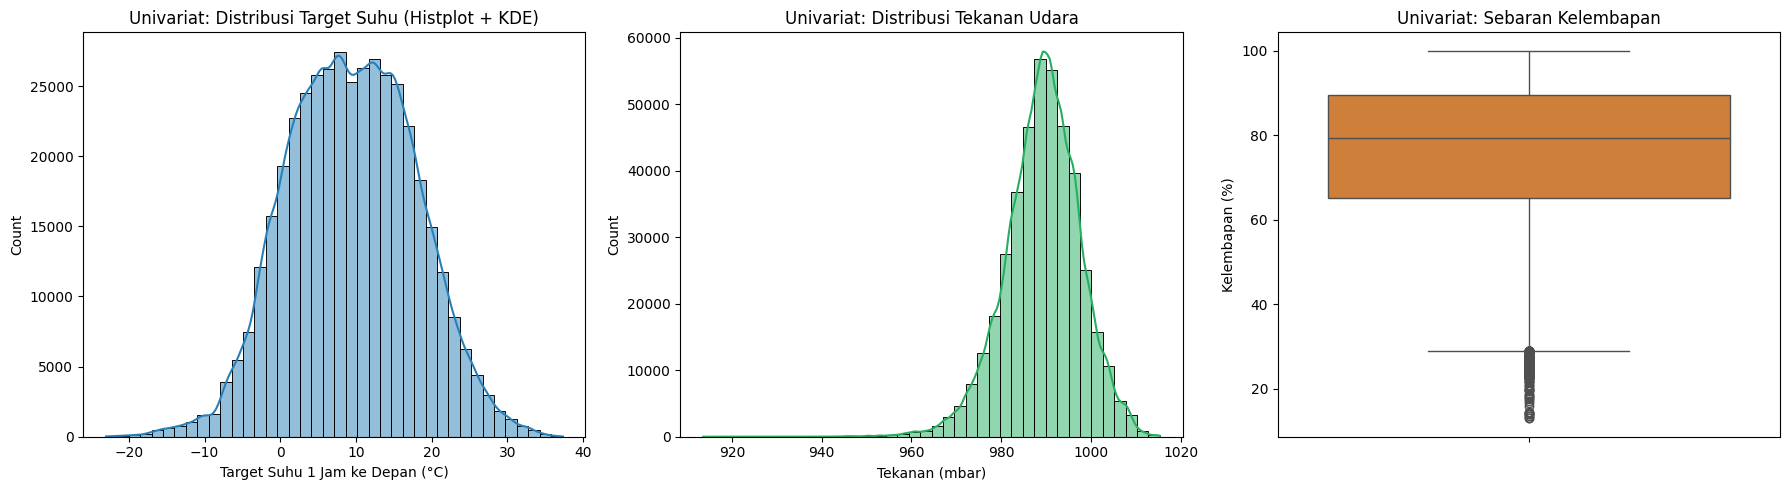

In [7]:
# ==============================================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ==============================================================================
# A. Analisis Univariat
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_clean["target_suhu_next_hour"], kde=True, ax=axes[0], color="#2980b9", bins=40)
axes[0].set_title("Univariat: Distribusi Target Suhu (Histplot + KDE)")
axes[0].set_xlabel("Target Suhu 1 Jam ke Depan (°C)")

sns.histplot(df_clean["p (mbar)"], kde=True, ax=axes[1], color="#27ae60", bins=40)
axes[1].set_title("Univariat: Distribusi Tekanan Udara")
axes[1].set_xlabel("Tekanan (mbar)")

sns.boxplot(y=df_clean["rh (%)"], ax=axes[2], color="#e67e22")
axes[2].set_title("Univariat: Sebaran Kelembapan")
axes[2].set_ylabel("Kelembapan (%)")

plt.tight_layout()
plt.show()

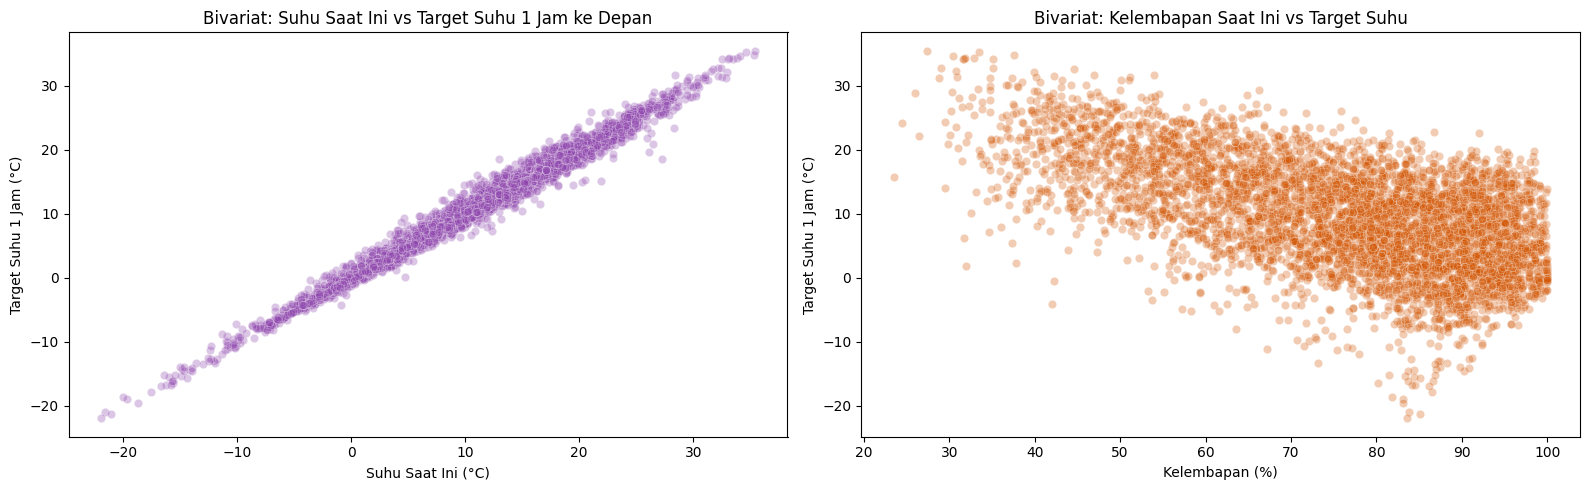

In [8]:
# B. Analisis Bivariat
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.scatterplot(data=df_sample, x="T (degC)", y="target_suhu_next_hour", alpha=0.3, ax=axes[0], color="#8e44ad")
axes[0].set_title("Bivariat: Suhu Saat Ini vs Target Suhu 1 Jam ke Depan")
axes[0].set_xlabel("Suhu Saat Ini (°C)")
axes[0].set_ylabel("Target Suhu 1 Jam (°C)")

sns.scatterplot(data=df_sample, x="rh (%)", y="target_suhu_next_hour", alpha=0.3, ax=axes[1], color="#d35400")
axes[1].set_title("Bivariat: Kelembapan Saat Ini vs Target Suhu")
axes[1].set_xlabel("Kelembapan (%)")
axes[1].set_ylabel("Target Suhu 1 Jam (°C)")

plt.tight_layout()
plt.show()

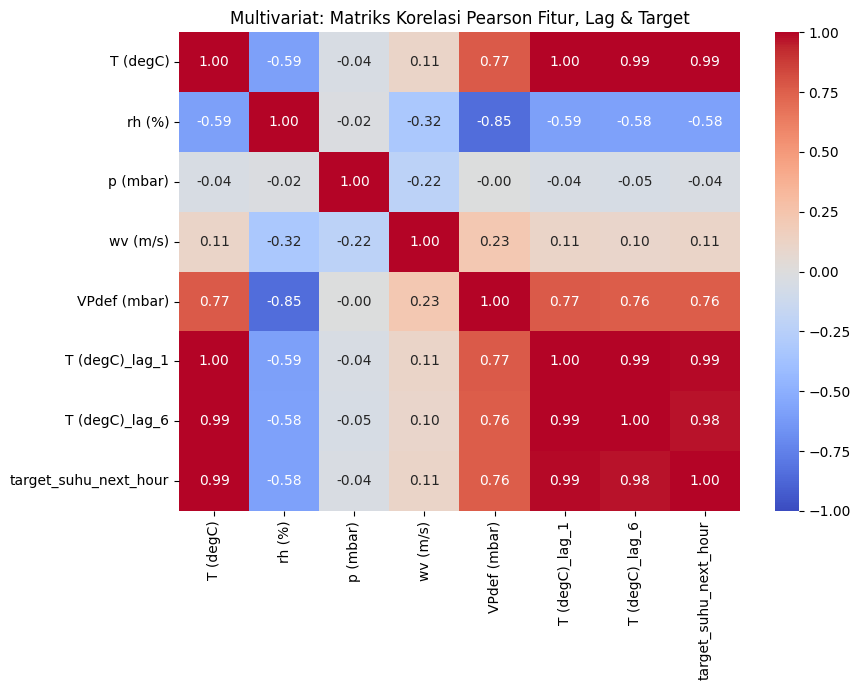

In [9]:
# C. Analisis Multivariat
corr_cols = [
    "T (degC)", "rh (%)", "p (mbar)", "wv (m/s)", "VPdef (mbar)",
    "T (degC)_lag_1", "T (degC)_lag_6", "target_suhu_next_hour"
]
plt.figure(figsize=(9, 7))
sns.heatmap(df_sample[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Multivariat: Matriks Korelasi Pearson Fitur, Lag & Target")
plt.tight_layout()
plt.show()

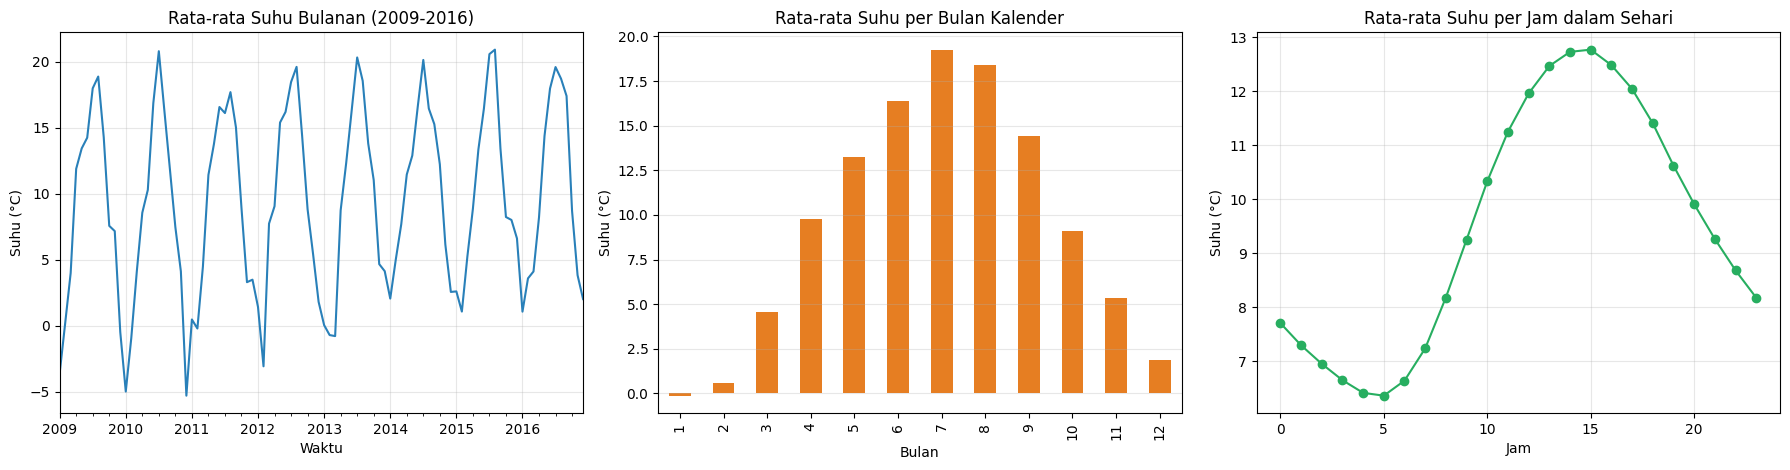

Bulan dengan rata-rata suhu tertinggi : Juli (19.26 °C)
Bulan dengan rata-rata suhu terendah  : Januari (-0.13 °C)
Jam dengan rata-rata suhu tertinggi   : 15.00 (12.77 °C)
Jam dengan rata-rata suhu terendah    : 05.00 (6.37 °C)
Korelasi suhu saat ini vs target (seluruh data bersih): 0.9927


In [10]:
# ==============================================================================
# [BARU] 3D. POLA WAKTU: SIKLUS HARIAN DAN MUSIMAN (EDA tambahan; df_clean tidak diubah)
# ==============================================================================
_t = df_clean[["Date Time", "T (degC)"]].copy()
_t["jam"] = _t["Date Time"].dt.hour
_t["bulan"] = _t["Date Time"].dt.month
rata_bulan = _t.groupby("bulan")["T (degC)"].mean()
rata_jam = _t.groupby("jam")["T (degC)"].mean()
rata_bulanan_seri = _t.set_index("Date Time")["T (degC)"].resample("MS").mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
rata_bulanan_seri.plot(ax=axes[0], color="#2980b9")
axes[0].set_title("Rata-rata Suhu Bulanan (2009-2016)")
axes[0].set_xlabel("Waktu")
axes[0].set_ylabel("Suhu (°C)")
axes[0].grid(True, alpha=0.3)

rata_bulan.plot(kind="bar", ax=axes[1], color="#e67e22")
axes[1].set_title("Rata-rata Suhu per Bulan Kalender")
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Suhu (°C)")
axes[1].grid(True, alpha=0.3, axis="y")

rata_jam.plot(marker="o", ax=axes[2], color="#27ae60")
axes[2].set_title("Rata-rata Suhu per Jam dalam Sehari")
axes[2].set_xlabel("Jam")
axes[2].set_ylabel("Suhu (°C)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/gambar_pola_waktu.png", dpi=150, bbox_inches="tight")
plt.show()

nama_bulan = {1: "Januari", 2: "Februari", 3: "Maret", 4: "April", 5: "Mei", 6: "Juni", 7: "Juli",
              8: "Agustus", 9: "September", 10: "Oktober", 11: "November", 12: "Desember"}
b_max, b_min = rata_bulan.idxmax(), rata_bulan.idxmin()
j_max, j_min = rata_jam.idxmax(), rata_jam.idxmin()
corr_full = df_clean["T (degC)"].corr(df_clean["target_suhu_next_hour"])
print(f"Bulan dengan rata-rata suhu tertinggi : {nama_bulan[b_max]} ({rata_bulan[b_max]:.2f} °C)")
print(f"Bulan dengan rata-rata suhu terendah  : {nama_bulan[b_min]} ({rata_bulan[b_min]:.2f} °C)")
print(f"Jam dengan rata-rata suhu tertinggi   : {j_max:02d}.00 ({rata_jam[j_max]:.2f} °C)")
print(f"Jam dengan rata-rata suhu terendah    : {j_min:02d}.00 ({rata_jam[j_min]:.2f} °C)")
print(f"Korelasi suhu saat ini vs target (seluruh data bersih): {corr_full:.4f}")

---
# F-G. Pembagian Data dan Model Utama XGBoost (Evaluation Design)

- **Pembagian data:** 80% baris pertama (kronologis) sebagai data latih dan 20% baris terakhir sebagai data uji, tanpa pengacakan.
- **Model utama:** `XGBRegressor` dengan hyperparameter tetap (tanpa *tuning*). Data uji pada `eval_set` hanya dipakai memantau kurva pembelajaran dan tidak memengaruhi pelatihan karena *early stopping* tidak digunakan.

# 4. Data Splitting dan Pelatihan XGBoost

In [ ]:
# ==============================================================================
# 4. DATA SPLITTING & TRAINING (XGBOOST REGRESSOR)
# ==============================================================================
ignore_cols = ["Date Time", "target_suhu_next_hour"]
feature_cols = [c for c in df_clean.columns if c not in ignore_cols]

X = df_clean[feature_cols]
y = df_clean["target_suhu_next_hour"]

# Temporal Splitting (80% train, 20% test tanpa pengacakan)
split_idx = int(len(df_clean) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("--- 3. DATA SPLITTING & PELATIHAN MODEL REGRESI ---")
print(f"Data Latih (Train) : {len(X_train):,} sampel")
print(f"Data Uji (Test)    : {len(X_test):,} sampel")

model = xgb.XGBRegressor(
    objective="reg:squarederror",
    eval_metric=["rmse", "mae"],
    n_estimators=200, # 200 pohon keputusan
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    tree_method="hist",
    n_jobs=-1,
)

print("\nMelatih model XGBoost Regressor untuk Prediksi Suhu...")
model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False,
)

--- 3. DATA SPLITTING & PELATIHAN MODEL REGRESI ---
Data Latih (Train) : 336,431 sampel
Data Uji (Test)    : 84,108 sampel

Melatih model XGBoost Regressor untuk Prediksi Suhu...


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=['rmse', 'mae'],
             feature_types=None, feature_weights=None, gamma=None,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=200, n_jobs=-1,
             num_parallel_tree=None, ...)

In [ ]:
def evaluate(y_true, y_pred):
    """Menghitung MAE, MSE, RMSE, dan R2."""
    mse_ = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse_,
            "RMSE": float(np.sqrt(mse_)), "R2": r2_score(y_true, y_pred)}

dt_all = df_clean["Date Time"]
dt_train, dt_test = dt_all.iloc[:split_idx], dt_all.iloc[split_idx:]
periode_latih = f"{dt_train.min():%d-%m-%Y %H:%M} s.d. {dt_train.max():%d-%m-%Y %H:%M}"
periode_uji = f"{dt_test.min():%d-%m-%Y %H:%M} s.d. {dt_test.max():%d-%m-%Y %H:%M}"
print("--- G1. AUDIT DATA LEAKAGE DAN EVALUATION DESIGN ---")
print(f"Periode data latih : {periode_latih}")
print(f"Periode data uji   : {periode_uji}")
print(f"Data uji sepenuhnya setelah data latih : {dt_train.max() < dt_test.min()}")

# Waktu target tiap baris df_clean (target = suhu pada baris ke-(i+6))
_tt = df["Date Time"].shift(-6)
target_time = _tt.loc[df.dropna().index].reset_index(drop=True)
leak_rows = int((target_time.iloc[:split_idx] >= dt_test.min()).sum())
print(f"Baris latih bertarget di periode uji: {leak_rows} dari {split_idx:,}")

# Cek lag hanya memakai masa lalu: lag_1 baris i sama dengan T baris i-1
lag_now = df_clean["T (degC)_lag_1"].iloc[1:].values
t_prev = df_clean["T (degC)"].iloc[:-1].values
lag_ok = bool(np.allclose(lag_now, t_prev))
print(f"lag_1 identik dengan suhu 10 menit sebelumnya: {lag_ok}")
tanpa_target = ("Date Time" not in feature_cols) and ("target_suhu_next_hour" not in feature_cols)
print(f"'Date Time' dan target tidak termasuk fitur: {tanpa_target}")
print(f"Jumlah fitur: {len(feature_cols)}")

# Rancangan validasi silang deret waktu (expanding window) pada DATA LATIH saja
tscv = TimeSeriesSplit(n_splits=5, gap=6)      # gap = horizon prediksi (6 baris = 60 menit)
print("\nLipatan validasi silang deret waktu (hanya pada data latih):")
print(f"{'Lipatan':<8}{'Latih (baris)':>15}{'Gap':>6}{'Validasi (baris)':>18}   Periode validasi")
for k, (tr_i, va_i) in enumerate(tscv.split(X_train), 1):
    print(f"{k:<8}{len(tr_i):>15,}{6:>6}{len(va_i):>18,}   "
          f"{dt_train.iloc[va_i[0]]:%d-%m-%Y} s.d. {dt_train.iloc[va_i[-1]]:%d-%m-%Y}")

--- G1. AUDIT DATA LEAKAGE DAN EVALUATION DESIGN ---
Periode data latih : 01-01-2009 01:10 s.d. 24-05-2015 18:50
Periode data uji   : 24-05-2015 19:00 s.d. 31-12-2016 23:00
Data uji sepenuhnya setelah data latih : True
Baris latih bertarget di periode uji: 6 dari 336,431
lag_1 identik dengan suhu 10 menit sebelumnya: True
'Date Time' dan target tidak termasuk fitur: True
Jumlah fitur: 33

Lipatan validasi silang deret waktu (hanya pada data latih):
Lipatan   Latih (baris)   Gap  Validasi (baris)   Periode validasi
1                56,070     6            56,071   25-01-2010 s.d. 17-02-2011
2               112,141     6            56,071   17-02-2011 s.d. 13-03-2012
3               168,212     6            56,071   13-03-2012 s.d. 06-04-2013
4               224,283     6            56,071   06-04-2013 s.d. 29-04-2014
5               280,354     6            56,071   29-04-2014 s.d. 24-05-2015


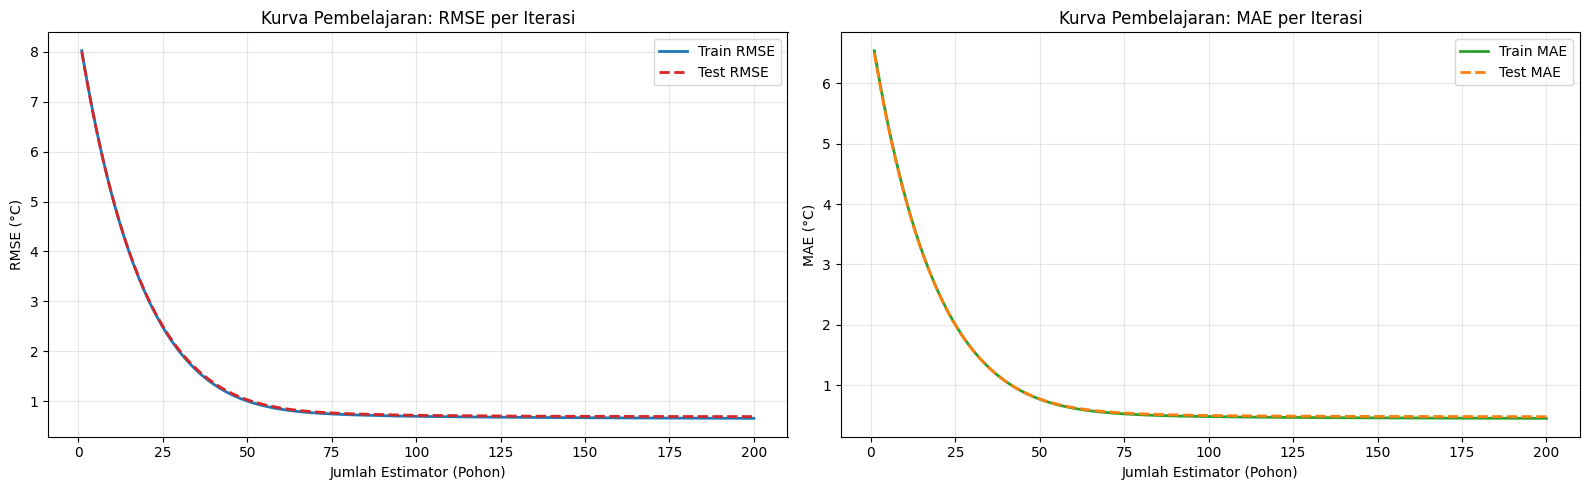

In [13]:
# ==============================================================================
# 5. VISUALISASI LEARNING CURVES (RMSE & MAE PER ITERASI)
# ==============================================================================
results = model.evals_result()
epochs = len(results["validation_0"]["rmse"])
x_axis = range(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot RMSE
axes[0].plot(x_axis, results["validation_0"]["rmse"], label="Train RMSE", color="#1f77b4", linewidth=2)
axes[0].plot(x_axis, results["validation_1"]["rmse"], label="Test RMSE", color="#d62728", linestyle="--", linewidth=2)
axes[0].set_title("Kurva Pembelajaran: RMSE per Iterasi")
axes[0].set_xlabel("Jumlah Estimator (Pohon)")
axes[0].set_ylabel("RMSE (°C)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot MAE
axes[1].plot(x_axis, results["validation_0"]["mae"], label="Train MAE", color="#2ca02c", linewidth=2)
axes[1].plot(x_axis, results["validation_1"]["mae"], label="Test MAE", color="#ff7f0e", linestyle="--", linewidth=2)
axes[1].set_title("Kurva Pembelajaran: MAE per Iterasi")
axes[1].set_xlabel("Jumlah Estimator (Pohon)")
axes[1].set_ylabel("MAE (°C)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


--- 4. HASIL EVALUASI METRIK REGRESI ---
Mean Absolute Error (MAE) : 0.4815 °C
Mean Squared Error (MSE)  : 0.4740
Root Mean Squared (RMSE)  : 0.6884 °C
R-squared (R2 Score)      : 0.9928



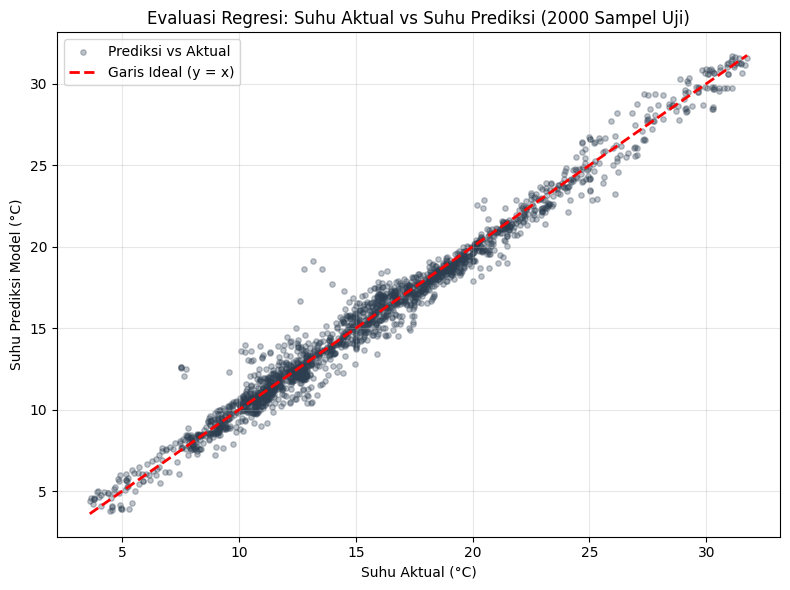

In [14]:
# ==============================================================================
# 6. EVALUASI METRIK REGRESI & PLOT HASIL
# ==============================================================================
preds = model.predict(X_test)

mae = mean_absolute_error(y_test, preds)
mse = mean_squared_error(y_test, preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, preds)

print("\n--- 4. HASIL EVALUASI METRIK REGRESI ---")
print(f"Mean Absolute Error (MAE) : {mae:.4f} °C")
print(f"Mean Squared Error (MSE)  : {mse:.4f}")
print(f"Root Mean Squared (RMSE)  : {rmse:.4f} °C")
print(f"R-squared (R2 Score)      : {r2:.4f}\n")

# Plot Scatter Aktual vs Prediksi & Garis Ideal
plt.figure(figsize=(8, 6))
plt.scatter(y_test.iloc[:2000], preds[:2000], alpha=0.3, color="#2c3e50", s=15, label="Prediksi vs Aktual")
min_val = min(y_test.iloc[:2000].min(), preds[:2000].min())
max_val = max(y_test.iloc[:2000].max(), preds[:2000].max())
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Garis Ideal (y = x)")
plt.title("Evaluasi Regresi: Suhu Aktual vs Suhu Prediksi (2000 Sampel Uji)")
plt.xlabel("Suhu Aktual (°C)")
plt.ylabel("Suhu Prediksi Model (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# ==============================================================================
# 7. TABEL HASIL PREDIKSI (SAMPEL NYATA VS PREDIKSI)
# ==============================================================================
df_eval = pd.DataFrame({
    "Waktu": df_clean.loc[X_test.index[:10], "Date Time"].values,
    "Suhu_Aktual_degC": y_test.iloc[:10].values.round(2),
    "Prediksi_Model_degC": preds[:10].round(2),
})

df_eval["Selisih_Error_degC"] = (df_eval["Prediksi_Model_degC"] - df_eval["Suhu_Aktual_degC"]).round(2)
df_eval["Error_Absolut"] = df_eval["Selisih_Error_degC"].abs()

print("--- 5. TABEL SAMPEL HASIL PREDIKSI (10 BARIS DATA UJI PERTAMA) ---")
print(df_eval.to_string(index=False))

--- 5. TABEL SAMPEL HASIL PREDIKSI (10 BARIS DATA UJI PERTAMA) ---
              Waktu  Suhu_Aktual_degC  Prediksi_Model_degC  Selisih_Error_degC  Error_Absolut
2015-05-24 19:00:00             16.92            16.680000               -0.24           0.24
2015-05-24 19:10:00             16.69            16.590000               -0.10           0.10
2015-05-24 19:20:00             16.51            16.379999               -0.13           0.13
2015-05-24 19:30:00             16.27            16.230000               -0.04           0.04
2015-05-24 19:40:00             16.09            16.240000                0.15           0.15
2015-05-24 19:50:00             15.98            15.860000               -0.12           0.12
2015-05-24 20:00:00             15.82            15.490000               -0.33           0.33
2015-05-24 20:10:00             15.87            15.290000               -0.58           0.58
2015-05-24 20:20:00             15.82            15.160000               -0.66         

---
# F. Baseline dan Initial Candidate Models

| Peran | Model | Alasan pemilihan |
|---|---|---|
| Baseline 1 | Rata-rata data latih | Pembanding paling sederhana; setiap model harus lebih baik dari menebak rata-rata. |
| Baseline 2 | **Persistensi** (suhu 1 jam lagi = suhu sekarang) | Pembanding standar untuk peramalan jangka sangat pendek; suhu sangat persisten. |
| Kandidat 1 | Ridge Regression (+ `StandardScaler` dalam *pipeline*) | Model linear sederhana dan cepat; menguji apakah hubungan cukup linear. |
| Kandidat 2 | Random Forest | Model pohon *bagging*, menangkap non-linearitas, pembanding langsung untuk XGBoost. |
| Kandidat 3 | XGBoost | Model utama proyek (*gradient boosting*), model yang sama dengan sel bagian 4. |

Semua model memakai **fitur dan pembagian data yang sama**. *Scaling* untuk Ridge dilakukan di dalam *pipeline* sehingga hanya dipelajari dari data latih (mencegah *data leakage*).

In [16]:
# ==============================================================================
# [BARU] F1. BASELINE DAN MODEL KANDIDAT - EVALUASI HOLDOUT (DATA UJI KRONOLOGIS)
# ==============================================================================
def make_xgb():
    """Konfigurasi sama dengan model utama pada bagian 4 (tanpa eval_set)."""
    return xgb.XGBRegressor(objective="reg:squarederror", n_estimators=200, learning_rate=0.05,
                            max_depth=6, subsample=0.8, colsample_bytree=0.8,
                            random_state=RANDOM_STATE, tree_method="hist", n_jobs=-1)

def make_rf():
    return RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=5,
                                 max_features=0.5, max_samples=0.3,
                                 n_jobs=-1, random_state=RANDOM_STATE)

MODELS = {
    "Baseline 1: Rata-rata data latih": lambda: DummyRegressor(strategy="mean"),
    "Baseline 2: Persistensi": None,          # prediksi = T (degC) saat ini
    "Kandidat 1: Ridge Regression": lambda: make_pipeline(
        StandardScaler(), Ridge(alpha=1.0)),
    "Kandidat 2: Random Forest": make_rf,
    "Kandidat 3: XGBoost": make_xgb,
}
NAMA_PERSISTENSI = "Baseline 2: Persistensi"

def fit_predict(name, X_tr, y_tr, X_te):
    if name == NAMA_PERSISTENSI:
        return X_te["T (degC)"].values.astype(float)
    m = MODELS[name]()
    m.fit(X_tr, y_tr)
    return m.predict(X_te)

hasil_holdout, pred_holdout = [], {}
for name in MODELS:
    if name == "Kandidat 3: XGBoost":
        p = preds                                   # prediksi model utama (sel bagian 6), angka identik
    else:
        p = fit_predict(name, X_train, y_train, X_test)
    pred_holdout[name] = p
    hasil_holdout.append({"Model": name, **evaluate(y_test, p)})
    print(f"{name:<36} MAE={hasil_holdout[-1]['MAE']:.4f}  RMSE={hasil_holdout[-1]['RMSE']:.4f}  R2={hasil_holdout[-1]['R2']:.4f}")

hasil_holdout = pd.DataFrame(hasil_holdout).set_index("Model")
hasil_holdout.to_csv(f"{OUT_DIR}/hasil_holdout.csv")

Baseline 1: Rata-rata data latih     MAE=6.8399  RMSE=8.4173  R2=-0.0816
Baseline 2: Persistensi              MAE=0.7205  RMSE=1.0142  R2=0.9843
Kandidat 1: Ridge Regression         MAE=0.6350  RMSE=7.7715  R2=0.0780
Kandidat 2: Random Forest            MAE=0.4751  RMSE=0.6909  R2=0.9927
Kandidat 3: XGBoost                  MAE=0.4815  RMSE=0.6884  R2=0.9928


In [ ]:
cv_detail = []
for name in MODELS:
    for k, (tr_i, va_i) in enumerate(tscv.split(X_train), 1):
        Xtr, Xva = X_train.iloc[tr_i], X_train.iloc[va_i]
        ytr, yva = y_train.iloc[tr_i], y_train.iloc[va_i]
        p = fit_predict(name, Xtr, ytr, Xva)
        cv_detail.append({"Model": name, "Lipatan": k, **evaluate(yva, p)})
    sub = pd.DataFrame([r for r in cv_detail if r["Model"] == name])
    r_m, r_s = sub["RMSE"].mean(), sub["RMSE"].std()
    print(f"{name:<34} RMSE CV = {r_m:.4f} ± {r_s:.4f}")

cv_detail = pd.DataFrame(cv_detail)
cv_detail.to_csv(f"{OUT_DIR}/hasil_cv_per_lipatan.csv", index=False)
cv_ringkas = cv_detail.groupby("Model")[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).loc[list(MODELS.keys())]
print("\nRingkasan validasi silang (rata-rata ± simpangan baku antar-lipatan):")
print(cv_ringkas.round(4).to_string())

Baseline 1: Rata-rata data latih   RMSE CV = 8.3463 ± 0.6902
Baseline 2: Persistensi            RMSE CV = 1.0215 ± 0.0465
Kandidat 1: Ridge Regression       RMSE CV = 0.7511 ± 0.0373
Kandidat 2: Random Forest          RMSE CV = 0.7155 ± 0.0360
Kandidat 3: XGBoost                RMSE CV = 0.7199 ± 0.0490

Ringkasan validasi silang (rata-rata ± simpangan baku antar-lipatan):
                                     MAE            RMSE              R2        
                                    mean     std    mean     std    mean     std
Model                                                                           
Baseline 1: Rata-rata data latih  6.8076  0.5809  8.3463  0.6902 -0.0352  0.0440
Baseline 2: Persistensi           0.7147  0.0385  1.0215  0.0465  0.9841  0.0036
Kandidat 1: Ridge Regression      0.5191  0.0139  0.7511  0.0373  0.9914  0.0018
Kandidat 2: Random Forest         0.4874  0.0231  0.7155  0.0360  0.9923  0.0014
Kandidat 3: XGBoost               0.4951  0.0283  0.7199 

--- TABEL HASIL EKSPERIMEN AWAL (urutan baris sama dengan tabel di laporan) ---
                           Model                                    Metode validasi             MAE            RMSE               R2 Skill vs persistensi
Baseline 1: Rata-rata data latih TimeSeriesSplit 5 lipatan, gap 6 (rata-rata ± std) 6.8076 ± 0.5809 8.3463 ± 0.6902 -0.0352 ± 0.0440              -7.1705
Baseline 1: Rata-rata data latih                Holdout kronologis 80/20 (data uji)          6.8399          8.4173          -0.0816              -7.2991
         Baseline 2: Persistensi TimeSeriesSplit 5 lipatan, gap 6 (rata-rata ± std) 0.7147 ± 0.0385 1.0215 ± 0.0465  0.9841 ± 0.0036               0.0000
         Baseline 2: Persistensi                Holdout kronologis 80/20 (data uji)          0.7205          1.0142           0.9843               0.0000
    Kandidat 1: Ridge Regression TimeSeriesSplit 5 lipatan, gap 6 (rata-rata ± std) 0.5191 ± 0.0139 0.7511 ± 0.0373  0.9914 ± 0.0018               0.2

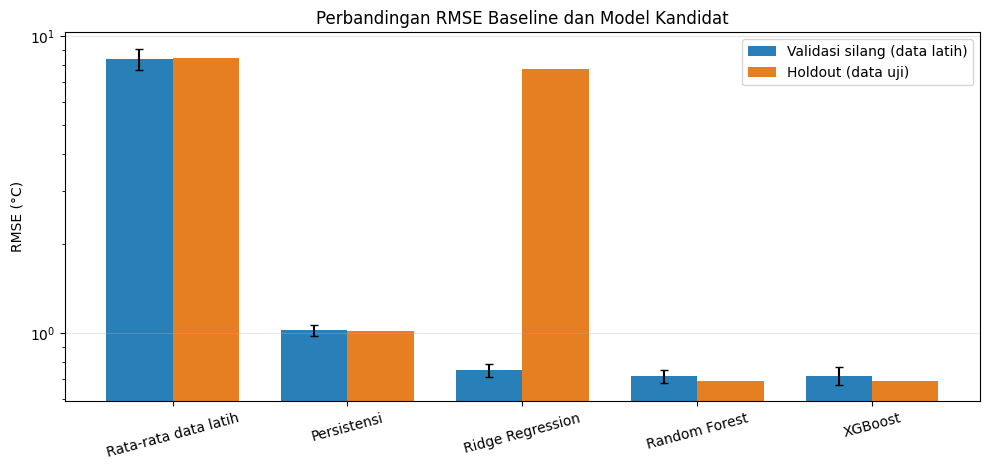

In [ ]:
rmse_p_holdout = hasil_holdout.loc[NAMA_PERSISTENSI, "RMSE"]
rmse_p_cv = cv_ringkas.loc[NAMA_PERSISTENSI, ("RMSE", "mean")]

baris = []
for name in MODELS:
    c = cv_ringkas.loc[name]
    h = hasil_holdout.loc[name]
    baris.append({"Model": name, "Metode validasi": "TimeSeriesSplit 5 lipatan, gap 6 (rata-rata ± std)",
                  "MAE": f"{c[('MAE','mean')]:.4f} ± {c[('MAE','std')]:.4f}",
                  "RMSE": f"{c[('RMSE','mean')]:.4f} ± {c[('RMSE','std')]:.4f}",
                  "R2": f"{c[('R2','mean')]:.4f} ± {c[('R2','std')]:.4f}",
                  "Skill vs persistensi": f"{1 - c[('RMSE','mean')] / rmse_p_cv:.4f}"})
    baris.append({"Model": name, "Metode validasi": "Holdout kronologis 80/20 (data uji)",
                  "MAE": f"{h['MAE']:.4f}", "RMSE": f"{h['RMSE']:.4f}", "R2": f"{h['R2']:.4f}",
                  "Skill vs persistensi": f"{1 - h['RMSE'] / rmse_p_holdout:.4f}"})
tabel_hasil = pd.DataFrame(baris)
tabel_hasil.to_csv(f"{OUT_DIR}/tabel_hasil_eksperimen_awal.csv", index=False)
print("--- TABEL HASIL EKSPERIMEN AWAL (urutan baris sama dengan tabel di laporan) ---")
print(tabel_hasil.to_string(index=False))
print("\nSkill score = 1 - RMSE_model / RMSE_persistensi (positif = lebih baik daripada persistensi).")

# Gambar perbandingan RMSE
fig, ax = plt.subplots(figsize=(10, 4.8))
nama_pendek = [n.split(": ")[1] for n in MODELS]
x = np.arange(len(MODELS)); w = 0.38
ax.bar(x - w/2, [cv_ringkas.loc[n, ("RMSE", "mean")] for n in MODELS], w,
       yerr=[cv_ringkas.loc[n, ("RMSE", "std")] for n in MODELS], capsize=3, label="Validasi silang (data latih)", color="#2980b9")
ax.bar(x + w/2, [hasil_holdout.loc[n, "RMSE"] for n in MODELS], w, label="Holdout (data uji)", color="#e67e22")
ax.set_xticks(x); ax.set_xticklabels(nama_pendek, rotation=15)
ax.set_ylabel("RMSE (°C)"); ax.set_title("Perbandingan RMSE Baseline dan Model Kandidat")
ax.set_yscale("log"); ax.grid(True, alpha=0.3, axis="y"); ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/gambar_perbandingan_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

---
# H. Initial Results and Analysis

Bagian berikut menganalisis hasil: dampak kelompok fitur (ablasi), fitur yang paling berperan, rincian galat menurut kondisi, dan sensitivitas hasil terhadap pembersihan data.

In [ ]:
cyc_cols = ["hour_sin", "hour_cos", "month_sin", "month_cos"]
lag_feat_cols = [c for c in feature_cols if "_lag_" in c]
orig_cols = [c for c in feature_cols if c not in cyc_cols and c not in lag_feat_cols]
print(f"Variabel asli: {len(orig_cols)} | Siklus: {len(cyc_cols)} | Lag: {len(lag_feat_cols)} | Total: {len(feature_cols)}")

skenario = {
    "A. Variabel asli saja":            orig_cols,
    "B. Variabel asli + siklus waktu":  orig_cols + cyc_cols,
    "C. Variabel asli + lag":           orig_cols + lag_feat_cols,
    "D. Lengkap (asli + siklus + lag)": feature_cols,
}
ablasi = []
for nama, cols in skenario.items():
    if nama.startswith("D."):
        p = preds                                   # model utama
    else:
        m = make_xgb(); m.fit(X_train[cols], y_train); p = m.predict(X_test[cols])
    ablasi.append({"Skenario": nama, "Jumlah fitur": len(cols), **evaluate(y_test, p)})
ablasi = pd.DataFrame(ablasi)
ablasi.to_csv(f"{OUT_DIR}/hasil_ablasi_fitur.csv", index=False)
print("\n--- TABEL ABLASI FITUR (urutan baris sama dengan tabel di laporan) ---")
print(ablasi[["Skenario", "Jumlah fitur", "MAE", "RMSE", "R2"]].round(4).to_string(index=False))

Variabel asli: 14 | Siklus: 4 | Lag: 15 | Total: 33

--- TABEL ABLASI FITUR (urutan baris sama dengan tabel di laporan) ---
                        Skenario  Jumlah fitur    MAE   RMSE     R2
           A. Variabel asli saja            14 0.6703 0.9333 0.9867
 B. Variabel asli + siklus waktu            18 0.4947 0.7016 0.9925
          C. Variabel asli + lag            29 0.5415 0.7818 0.9907
D. Lengkap (asli + siklus + lag)            33 0.4815 0.6884 0.9928


--- 15 FITUR TERPENTING (porsi total gain) ---
T (degC)              47.26 %
VPmax (mbar)          32.62 %
T (degC)_lag_1        17.65 %
Tpot (K)                1.3 %
T (degC)_lag_6         0.16 %
hour_cos               0.16 %
hour_sin               0.16 %
H2OC (mmol/mol)        0.07 %
sh (g/kg)              0.06 %
VPact (mbar)           0.05 %
month_cos              0.05 %
T (degC)_lag_3         0.05 %
wd (deg)               0.04 %
max. wv (m/s)          0.04 %
VPdef (mbar)_lag_6     0.04 %

Porsi gain per kelompok fitur:
  Variabel asli : 81.55 %
  Lag           : 18.07 %
  Siklus waktu  : 0.38 %


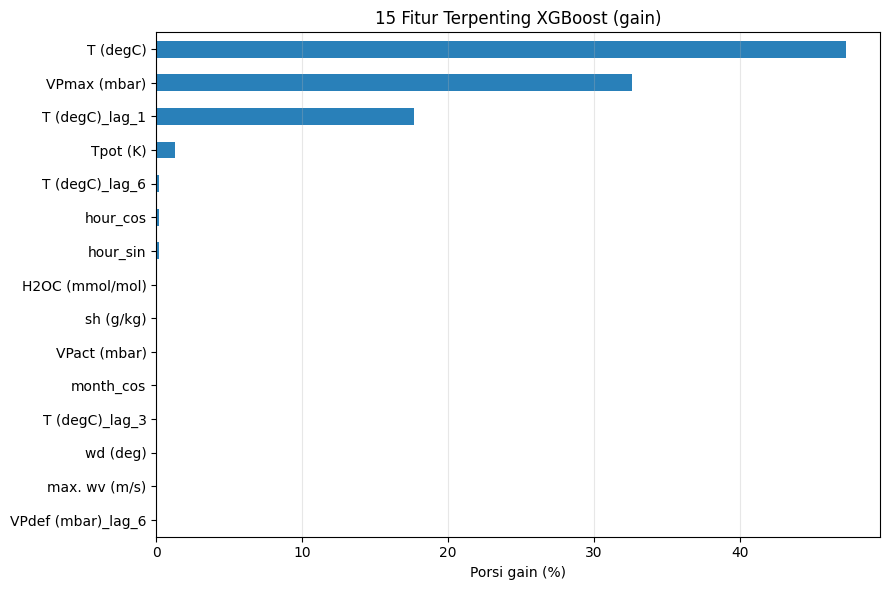

In [ ]:
gain = pd.Series(model.get_booster().get_score(importance_type="gain")).reindex(feature_cols).fillna(0.0)
imp = (gain / gain.sum()).sort_values(ascending=False)

print("--- 15 FITUR TERPENTING (porsi total gain) ---")
print((imp.head(15) * 100).round(2).astype(str).add(" %").to_string())

grup_share = {
    "Variabel asli": imp[orig_cols].sum() * 100,
    "Lag": imp[lag_feat_cols].sum() * 100,
    "Siklus waktu": imp[cyc_cols].sum() * 100,
}
print("\nPorsi gain per kelompok fitur:")
for k, v in grup_share.items():
    print(f"  {k:<14}: {v:.2f} %")
imp.to_csv(f"{OUT_DIR}/feature_importance_gain.csv", header=["porsi_gain"])

fig, ax = plt.subplots(figsize=(9, 6))
imp.head(15)[::-1].mul(100).plot(kind="barh", ax=ax, color="#2980b9")
ax.set_xlabel("Porsi gain (%)"); ax.set_title("15 Fitur Terpenting XGBoost (gain)")
ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/gambar_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

--- TABEL ANALISIS GALAT (urutan baris sama dengan tabel di laporan) ---
           Kelompok           Kategori     n  MAE_XGBoost  MAE_Persistensi
         Waktu hari  Dini hari (00-05) 21024       0.3878           0.4835
         Waktu hari       Pagi (06-11) 21016       0.5841           1.0227
         Waktu hari Siang-sore (12-17) 21019       0.5413           0.6601
         Waktu hari      Malam (18-23) 21049       0.4129           0.7159
              Musim   Dingin (Des-Feb) 17563       0.4231           0.5230
              Musim     Semi (Mar-Mei) 14286       0.4716           0.7345
              Musim    Panas (Jun-Agu) 26496       0.5641           0.9116
              Musim    Gugur (Sep-Nov) 25763       0.4417           0.6509
Rentang suhu aktual             < 0 °C  6066       0.3832           0.5031
Rentang suhu aktual         0 - <10 °C 32015       0.4189           0.5555
Rentang suhu aktual        10 - <20 °C 33765       0.5074           0.7916
Rentang suhu aktual        

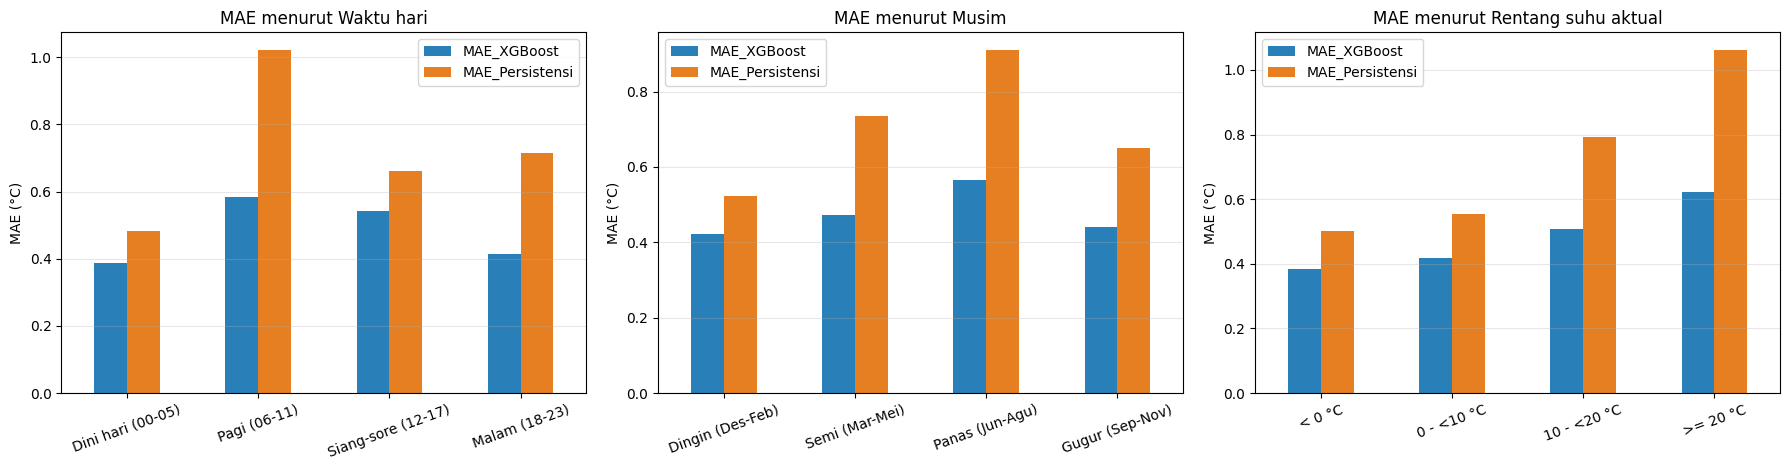

In [ ]:
err = pd.DataFrame({
    "waktu": dt_test.reset_index(drop=True),          # waktu pengamatan (prediksi untuk 60 menit setelahnya)
    "aktual": y_test.values,
    "suhu_sekarang": X_test["T (degC)"].values,
    "xgb": preds,
})
err["abs_xgb"] = (err["aktual"] - err["xgb"]).abs()
err["abs_persistensi"] = (err["aktual"] - err["suhu_sekarang"]).abs()

jam = err["waktu"].dt.hour
bulan = err["waktu"].dt.month
err["Waktu hari"] = pd.cut(jam, bins=[-1, 5, 11, 17, 23],
                           labels=["Dini hari (00-05)", "Pagi (06-11)", "Siang-sore (12-17)", "Malam (18-23)"])
err["Musim"] = bulan.map({12: "Dingin (Des-Feb)", 1: "Dingin (Des-Feb)", 2: "Dingin (Des-Feb)",
                          3: "Semi (Mar-Mei)", 4: "Semi (Mar-Mei)", 5: "Semi (Mar-Mei)",
                          6: "Panas (Jun-Agu)", 7: "Panas (Jun-Agu)", 8: "Panas (Jun-Agu)",
                          9: "Gugur (Sep-Nov)", 10: "Gugur (Sep-Nov)", 11: "Gugur (Sep-Nov)"})
err["Rentang suhu aktual"] = pd.cut(err["aktual"], bins=[-np.inf, 0, 10, 20, np.inf], right=False,
                                    labels=["< 0 °C", "0 - <10 °C", "10 - <20 °C", ">= 20 °C"])

potongan = []
urutan_kelompok = [("Waktu hari", ["Dini hari (00-05)", "Pagi (06-11)", "Siang-sore (12-17)", "Malam (18-23)"]),
                   ("Musim", ["Dingin (Des-Feb)", "Semi (Mar-Mei)", "Panas (Jun-Agu)", "Gugur (Sep-Nov)"]),
                   ("Rentang suhu aktual", ["< 0 °C", "0 - <10 °C", "10 - <20 °C", ">= 20 °C"])]
for kolom, urutan in urutan_kelompok:
    g = err.groupby(kolom, observed=False).agg(n=("aktual", "size"), MAE_XGBoost=("abs_xgb", "mean"),
                                               MAE_Persistensi=("abs_persistensi", "mean"))
    g = g.reindex(urutan)                               # menjaga urutan; kategori tanpa data bernilai NaN
    for kategori in urutan:
        potongan.append({"Kelompok": kolom, "Kategori": kategori,
                         "n": 0 if pd.isna(g.loc[kategori, "n"]) else int(g.loc[kategori, "n"]),
                         "MAE_XGBoost": g.loc[kategori, "MAE_XGBoost"],
                         "MAE_Persistensi": g.loc[kategori, "MAE_Persistensi"]})
tabel_galat = pd.DataFrame(potongan)
tabel_galat.to_csv(f"{OUT_DIR}/analisis_galat.csv", index=False)
print("--- TABEL ANALISIS GALAT (urutan baris sama dengan tabel di laporan) ---")
print(tabel_galat.round(4).to_string(index=False))

pct_gt2 = (err["abs_xgb"] > 2).mean() * 100
print(f"\nProporsi prediksi XGBoost dengan |galat| > 2 °C : {pct_gt2:.2f} %")
print(f"Galat absolut maksimum XGBoost                  : {err['abs_xgb'].max():.2f} °C")
baris_max = tabel_galat.loc[tabel_galat["MAE_XGBoost"].idxmax()]
baris_min = tabel_galat.loc[tabel_galat["MAE_XGBoost"].idxmin()]
print(f"MAE XGBoost tertinggi : {baris_max['Kategori']} ({baris_max['MAE_XGBoost']:.4f} °C)")
print(f"MAE XGBoost terendah  : {baris_min['Kategori']} ({baris_min['MAE_XGBoost']:.4f} °C)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (kolom, urutan) in zip(axes, urutan_kelompok):
    sub = tabel_galat[tabel_galat["Kelompok"] == kolom].set_index("Kategori").loc[urutan]
    sub[["MAE_XGBoost", "MAE_Persistensi"]].plot(kind="bar", ax=ax, color=["#2980b9", "#e67e22"])
    ax.set_title(f"MAE menurut {kolom}"); ax.set_ylabel("MAE (°C)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20); ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/gambar_analisis_galat.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
base_cols = df.columns[:15].tolist()                       
d = df[base_cols].copy()
n_awal = len(d)
d = d.drop_duplicates(subset="Date Time", keep="first")
n_dup_dibuang = n_awal - len(d)

for c in ["wv (m/s)", "max. wv (m/s)"]:
    d.loc[d[c] < 0, c] = np.nan
    d[c] = d[c].ffill().bfill()

d = d.sort_values("Date Time").reset_index(drop=True)
d["target_suhu_next_hour"] = d["T (degC)"].shift(-6)
d["hour_sin"] = np.sin(2 * np.pi * d["Date Time"].dt.hour / 24.0)
d["hour_cos"] = np.cos(2 * np.pi * d["Date Time"].dt.hour / 24.0)
d["month_sin"] = np.sin(2 * np.pi * d["Date Time"].dt.month / 12.0)
d["month_cos"] = np.cos(2 * np.pi * d["Date Time"].dt.month / 12.0)
for col in lag_cols:
    for lag in [1, 3, 6]:
        d[f"{col}_lag_{lag}"] = d[col].shift(lag)

tm = d["Date Time"]
valid = (((tm.shift(-6) - tm) == pd.Timedelta(minutes=60)) & ((tm - tm.shift(6)) == pd.Timedelta(minutes=60)) &
         ((tm - tm.shift(3)) == pd.Timedelta(minutes=30)) & ((tm - tm.shift(1)) == pd.Timedelta(minutes=10)))
d2 = d.dropna()
n_interval_dibuang = int(len(d2) - valid.loc[d2.index].sum())
d2 = d2[valid.loc[d2.index]].reset_index(drop=True)

split2 = int(len(d2) * 0.8)
tr2 = d2.iloc[:split2 - 6]                                  # buang 6 baris terakhir latih (gap)
te2 = d2.iloc[split2:]
m2 = make_xgb(); m2.fit(tr2[feature_cols], tr2["target_suhu_next_hour"])
p2 = m2.predict(te2[feature_cols])
eval_bersih = evaluate(te2["target_suhu_next_hour"], p2)
eval_persist2 = evaluate(te2["target_suhu_next_hour"], te2["T (degC)"].values)

sens = pd.DataFrame([
    {"Pipeline": "Utama (sesuai laporan awal)", "Baris latih": len(X_train), "Baris uji": len(X_test),
     **{k: hasil_holdout.loc["Kandidat 3: XGBoost", k] for k in ["MAE", "RMSE", "R2"]}},
    {"Pipeline": "Data bersih (H4)", "Baris latih": len(tr2), "Baris uji": len(te2),
     **{k: eval_bersih[k] for k in ["MAE", "RMSE", "R2"]}},
])
sens.to_csv(f"{OUT_DIR}/hasil_sensitivitas_data_bersih.csv", index=False)
print(f"Baris dibuang karena timestamp duplikat      : {n_dup_dibuang}")
print(f"Baris dibuang karena interval waktu tidak valid: {n_interval_dibuang}")
print(f"RMSE persistensi pada data uji pipeline bersih : {eval_persist2['RMSE']:.4f} °C")
print("\n--- TABEL SENSITIVITAS (urutan baris sama dengan tabel di laporan) ---")
print(sens.round(4).to_string(index=False))
print("\nCatatan: data uji kedua pipeline tidak persis sama (jumlah baris berbeda), sehingga selisih kecil bersifat indikatif.")

Baris dibuang karena timestamp duplikat      : 327
Baris dibuang karena interval waktu tidak valid: 60
RMSE persistensi pada data uji pipeline bersih : 1.0142 °C

--- TABEL SENSITIVITAS (urutan baris sama dengan tabel di laporan) ---
                   Pipeline  Baris latih  Baris uji    MAE   RMSE     R2
Utama (sesuai laporan awal)       336431      84108 0.4815 0.6884 0.9928
           Data bersih (H4)       336115      84031 0.4821 0.6894 0.9928

Catatan: data uji kedua pipeline tidak persis sama (jumlah baris berbeda), sehingga selisih kecil bersifat indikatif.


---
# I. Dokumentasi, Lembar Isian Laporan, dan Rencana Pasca-UTS

Sel berikut mengumpulkan **seluruh angka tunggal** yang dikutip di laporan (kode `S01`-`S32`) dan menyimpannya ke `hasil_eksperimen/lembar_isian_laporan.txt`. Tabel hasil dicetak pada sel F3, H1, H3, dan H4 dengan urutan baris yang sama seperti pada laporan.

In [ ]:
isian = {}
def catat(kode, label, fungsi):
    try:
        isian[kode] = (label, str(fungsi()))
    except Exception as e:
        isian[kode] = (label, f"(tidak tersedia: {e})")

catat("S01", "Timestamp duplikat (Date Time sama)", lambda: f"{dup_ts:,}")
catat("S02", "Baris dengan max. wv (m/s) < 0", lambda: f"{neg_maxwv:,}")
catat("S03", "Jumlah selisih waktu antar-baris yang bukan 10 menit", lambda: f"{n_not10:,}")
catat("S04", "Selisih waktu antar-baris terbesar", lambda: f"{max_gap}")
catat("S05", "Baris dengan wv (m/s) > max. wv (m/s)", lambda: f"{wv_gt_max:,}")
catat("S06", "Rentang rh (%)", lambda: f"{rh_min:.2f} s.d. {rh_max:.2f}")
catat("S07", "Bulan dengan rata-rata suhu tertinggi", lambda: f"{nama_bulan[b_max]} ({rata_bulan[b_max]:.2f} °C)")
catat("S08", "Bulan dengan rata-rata suhu terendah", lambda: f"{nama_bulan[b_min]} ({rata_bulan[b_min]:.2f} °C)")
catat("S09", "Jam dengan rata-rata suhu tertinggi", lambda: f"{j_max:02d}.00 ({rata_jam[j_max]:.2f} °C)")
catat("S10", "Jam dengan rata-rata suhu terendah", lambda: f"{j_min:02d}.00 ({rata_jam[j_min]:.2f} °C)")
catat("S11", "Korelasi suhu saat ini vs target (seluruh data bersih)", lambda: f"{corr_full:.4f}")
catat("S12", "Periode data latih", lambda: periode_latih)
catat("S13", "Periode data uji", lambda: periode_uji)
catat("S14", "Baris latih dengan waktu target di periode uji", lambda: f"{leak_rows}")
catat("S15", "Skill score RMSE XGBoost vs persistensi (holdout)",
      lambda: f"{1 - hasil_holdout.loc['Kandidat 3: XGBoost','RMSE'] / rmse_p_holdout:.4f}")
catat("S16", "Skill score RMSE XGBoost vs persistensi (rata-rata CV)",
      lambda: f"{1 - cv_ringkas.loc['Kandidat 3: XGBoost', ('RMSE','mean')] / rmse_p_cv:.4f}")
catat("S17", "Model dengan RMSE holdout terendah", lambda: hasil_holdout["RMSE"].idxmin())
catat("S18", "Model dengan RMSE CV terendah", lambda: cv_ringkas[("RMSE", "mean")].idxmin())
catat("S19", "RMSE persistensi pada data uji (°C)", lambda: f"{rmse_p_holdout:.4f}")
catat("S20", "MAE persistensi pada data uji (°C)", lambda: f"{hasil_holdout.loc[NAMA_PERSISTENSI,'MAE']:.4f}")
catat("S21", "Skenario ablasi dengan RMSE terendah", lambda: ablasi.loc[ablasi["RMSE"].idxmin(), "Skenario"])
catat("S22", "Fitur terpenting ke-1 (porsi gain)", lambda: f"{imp.index[0]} ({imp.iloc[0]*100:.2f} %)")
catat("S23", "Fitur terpenting ke-2 (porsi gain)", lambda: f"{imp.index[1]} ({imp.iloc[1]*100:.2f} %)")
catat("S24", "Fitur terpenting ke-3 (porsi gain)", lambda: f"{imp.index[2]} ({imp.iloc[2]*100:.2f} %)")
catat("S25", "Porsi gain kelompok variabel asli", lambda: f"{grup_share['Variabel asli']:.2f} %")
catat("S26", "Porsi gain kelompok lag", lambda: f"{grup_share['Lag']:.2f} %")
catat("S27", "Porsi gain kelompok siklus waktu", lambda: f"{grup_share['Siklus waktu']:.2f} %")
catat("S28", "Proporsi prediksi dengan |galat| > 2 °C", lambda: f"{pct_gt2:.2f} %")
catat("S29", "Kategori dengan MAE XGBoost tertinggi", lambda: f"{baris_max['Kategori']} ({baris_max['MAE_XGBoost']:.4f} °C)")
catat("S30", "Kategori dengan MAE XGBoost terendah", lambda: f"{baris_min['Kategori']} ({baris_min['MAE_XGBoost']:.4f} °C)")
catat("S31", "Baris dibuang karena timestamp duplikat (H4)", lambda: f"{n_dup_dibuang:,}")
catat("S32", "Baris dibuang karena interval waktu tidak valid (H4)", lambda: f"{n_interval_dibuang:,}")

teks = ["LEMBAR ISIAN LAPORAN - salin nilai berikut ke bagian bertanda kuning [Sxx] pada laporan", "=" * 78]
for kode, (label, nilai) in isian.items():
    teks.append(f"{kode} | {label:<58} | {nilai}")
teks = "\n".join(teks)
print(teks)
with open(f"{OUT_DIR}/lembar_isian_laporan.txt", "w", encoding="utf-8") as f:
    f.write(teks)

print("\nBerkas keluaran di folder", OUT_DIR, ":")
for nama_berkas in sorted(os.listdir(OUT_DIR)):
    print(" -", nama_berkas)

LEMBAR ISIAN LAPORAN - salin nilai berikut ke bagian bertanda kuning [Sxx] pada laporan
S01 | Timestamp duplikat (Date Time sama)                        | 327
S02 | Baris dengan max. wv (m/s) < 0                             | 20
S03 | Jumlah selisih waktu antar-baris yang bukan 10 menit       | 332
S04 | Selisih waktu antar-baris terbesar                         | 3 days 02:20:00
S05 | Baris dengan wv (m/s) > max. wv (m/s)                      | 2
S06 | Rentang rh (%)                                             | 12.95 s.d. 100.00
S07 | Bulan dengan rata-rata suhu tertinggi                      | Juli (19.26 °C)
S08 | Bulan dengan rata-rata suhu terendah                       | Januari (-0.13 °C)
S09 | Jam dengan rata-rata suhu tertinggi                        | 15.00 (12.77 °C)
S10 | Jam dengan rata-rata suhu terendah                         | 05.00 (6.37 °C)
S11 | Korelasi suhu saat ini vs target (seluruh data bersih)     | 0.9927
S12 | Periode data latih                             

## Rencana pekerjaan pasca-UTS menuju final project (UAS)

| Tahap | Pekerjaan | Luaran |
|---|---|---|
| 1 | Perbaiki data: hapus timestamp duplikat, tangani `max. wv`, verifikasi interval 10 menit pada pipeline utama (lihat H4) | Pipeline data bersih yang menjadi standar |
| 2 | Perkaya fitur: rata-rata dan simpangan baku bergulir, perubahan tekanan 1 jam, sinus-kosinus arah angin, *lag* lebih panjang (12, 24, 144) | Himpunan fitur baru dan hasil ablasi |
| 3 | Ubah target menjadi **perubahan suhu** (T t+60 dikurangi T sekarang) agar model fokus pada selisih | Perbandingan target absolut vs target selisih |
| 4 | *Tuning* hyperparameter XGBoost (dan Random Forest) dengan `TimeSeriesSplit` + gap, tanpa menyentuh data uji | Hyperparameter terpilih dan tabel *tuning* |
| 5 | Model kandidat tambahan: LightGBM, Gradient Boosting sklearn, Lasso/ElasticNet; perluas horizon (30, 120, 180 menit) | Tabel perbandingan model akhir |
| 6 | Analisis galat lanjutan dan interpretasi (SHAP/permutation importance), pengujian pada periode ekstrem | Bagian analisis dan keterbatasan final |
| 7 | Finalisasi notebook, repositori GitHub, laporan final, dan presentasi | Dokumen dan kode final |